# Reading native McStas scans

This tutorial builds an instrument with McStasScript, writes it with `write_full_instrument()`, runs scans with notebook `!mcrun` commands, and reads the resulting files with `ms.load_scan()`. The instrument builder, native runner, and data reader are separate: reading an existing scan does not rerun McStas or require the instrument object.

You need a McStasScript version with `load_scan()`, **McStas 3.10 or newer**, a working C compiler, and a Jupyter kernel whose environment provides `mcrun`. The examples below were tested with McStas 3.10.0. Native options and output layouts differ between releases; the [scan-result guide](../user_guide/scan_results.rst) describes those differences.

We will read a one-parameter scan, a paired trajectory, an unequal Cartesian grid, and a NeXus scan. No Python scan-execution API is used.

In [1]:
%matplotlib inline
from pathlib import Path
import shutil

import matplotlib.pyplot as plt
import numpy as np
import mcstasscript as ms

assert shutil.which('mcrun'), 'Activate an environment containing McStas before starting Jupyter.'
!mcrun --version
assert _exit_code == 0, 'mcrun could not be started.'

3.10.0


## Choose a name for this set of scans

Change `run_name` to choose your own output name. The instrument goes under `run_folder`, and the named scan results go under `data_folder`. Paths are relative to the notebook kernel's working directory.

The setup refuses to reuse an existing result directory. To run the notebook again, choose a new `run_name`; this avoids accidentally loading results left over from an earlier run.

In [2]:
run_name = 'my_named_scan_examples'
run_path = Path('run_folder') / run_name
output_root = Path('data_folder') / run_name
if output_root.exists():
    raise FileExistsError(f'{output_root} already exists. Choose a new run_name.')
run_path.mkdir(parents=True, exist_ok=True)
output_root.mkdir(parents=True)

wavelength_output = output_root / 'my_wavelength_scan'
paired_output = output_root / 'my_paired_scan'
grid_output = output_root / 'my_grid_scan'
nexus_output = output_root / 'my_nexus_scan'

## Build and write the instrument

A `Source_simple` sends neutrons to a wavelength monitor one metre downstream. Two instrument parameters control the source: `wavelength` moves the spectrum, and `source_flux` scales its intensity. Varying the source brightness makes the paired and grid examples easy to interpret without introducing a sample model.

Component string values such as the monitor filename are C string literals, hence the extra quotes around `spectrum.dat`. `write_full_instrument()` writes the `.instr` file but does not compile or run it.

In [3]:
instrument = ms.McStas_instr('scan_reading_demo', input_path=str(run_path))
wavelength = instrument.add_parameter(
    'wavelength', value=3.0, unit='angstrom', comment='Mean source wavelength [AA]')
source_flux = instrument.add_parameter(
    'source_flux', value=1e7, comment='Source brightness scaling')

source = instrument.add_component('source', 'Source_simple')
source.set_parameters(
    radius=0.001, dist=1.0, focus_xw=0.01, focus_yh=0.01,
    lambda0=wavelength, dlambda=0.1, flux=source_flux)

monitor = instrument.add_component('spectrum', 'L_monitor')
monitor.set_parameters(
    xwidth=0.02, yheight=0.02, nL=24, Lmin=1.0, Lmax=7.0,
    filename='"spectrum.dat"')
monitor.set_AT([0, 0, 1], RELATIVE=source)

instrument.write_full_instrument()
instrument_file = run_path / 'scan_reading_demo.instr'
assert instrument_file.is_file()
print(f'Instrument written to {instrument_file}')

Instrument written to run_folder/my_named_scan_examples/scan_reading_demo.instr


## A one-parameter wavelength scan

The `!` prefix runs a shell command from an IPython notebook. Here `-N 5 wavelength=2,6` requests five equally spaced wavelengths, including both endpoints. `--dir` gives the scan a custom output name, and `--ncount` is the number of particles **per point**.

Run settings for these external commands belong on the command line, not in `instrument.settings()`. Compilation and simulation messages are saved to a named log. The exit-code check catches command failures, but a zero native exit code alone does not prove that every point succeeded; we also inspect the loaded results.

In [4]:
wavelength_log = output_root / 'wavelength.log'
!mcrun --force-compile --format=McCode --seed=314159 --ncount=50000 --dir="{wavelength_output}" "{instrument_file}" -N 5 wavelength=2,6 > "{wavelength_log}" 2>&1
if _exit_code != 0:
    raise RuntimeError(wavelength_log.read_text())
print(f'Native scan output: {wavelength_output}')

Native scan output: data_folder/my_named_scan_examples/my_wavelength_scan


### Read the scan, then inspect its scalar summaries

Use `load_scan()`, not the single-run `load_data()` function. The reader obtains coordinates from point metadata and the native summary; do not manually assume that the summary's column order is correct. A scan stores ordered point records, not an automatically reshaped array.

`dataset('spectrum')` selects a monitor across the scan. Its integrated intensity and error are one scalar per point. Reading these summaries does **not** load every detector histogram.

In [5]:
scan = ms.load_scan(wavelength_output)
spectrum = scan.dataset('spectrum')
assert len(scan.points) == 5
np.testing.assert_allclose(scan.coordinates['wavelength'].astype(float), [2, 3, 4, 5, 6])
assert spectrum.valid.all() and np.all(spectrum.total_I > 0)
assert all(not point.is_loaded for point in scan.points)

print('Point  Wavelength [AA]  Execution status  Full data loaded')
for point in scan.points:
    print(f'{point.point_id:5}  {point.parameters["wavelength"]:15g}  '
          f'{point.status:16}  {point.is_loaded}')
print('Total intensity:', spectrum.total_I)
print('Total error:    ', spectrum.total_E)
print('Array status:  ', [point.data_status for point in scan.points])

Point  Wavelength [AA]  Execution status  Full data loaded
    0                2  unknown           False
    1                3  unknown           False
    2                4  unknown           False
    3                5  unknown           False
    4                6  unknown           False
Total intensity: [6.28297 6.28297 6.28297 6.28297 6.28297]
Total error:     [0.0280983 0.0280983 0.0280983 0.0280983 0.0280983]
Array status:   ['unknown', 'unknown', 'unknown', 'unknown', 'unknown']


### Plot a summary and read selected detector spectra

The monitor covers the full wavelength range, so its total intensity should stay nearly constant when only the mean wavelength changes. The **histogram peak**, rather than the integral, moves. The first plot uses scalar summaries only; the second explicitly loads three point datasets to show the moving peak.

Each `point.data` is a list-compatible `McStasDataCollection`; `.find('spectrum')` returns its original monitor dataset. Repeated access returns the same cached collection.

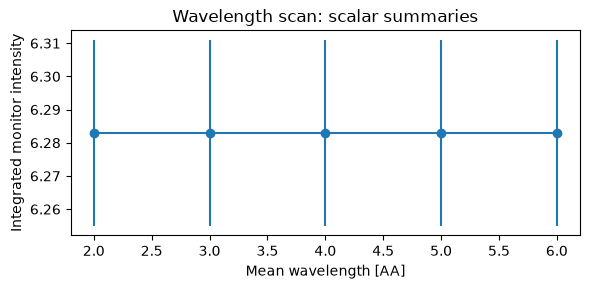

In [6]:
valid = spectrum.valid & spectrum.validity('total_E')
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(spectrum.coordinates['wavelength'][valid].astype(float),
            spectrum.total_I[valid], yerr=spectrum.total_E[valid], fmt='o-')
ax.set(xlabel='Mean wavelength [AA]', ylabel='Integrated monitor intensity',
       title='Wavelength scan: scalar summaries')
fig.tight_layout()
plt.show()
assert all(not point.is_loaded for point in scan.points)

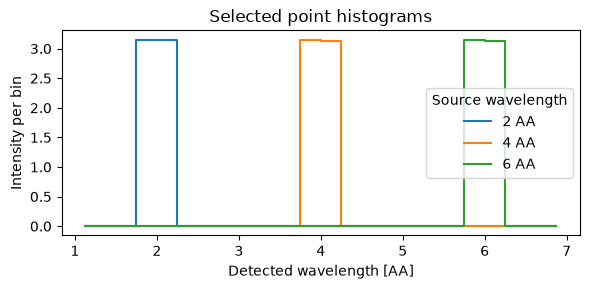

Histograms now cached: [True, False, True, False, True]


In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
for point in scan.points[::2]:
    point_data = point.data
    detector = point_data.find('spectrum')
    assert isinstance(point_data, ms.McStasDataCollection)
    assert point.data is point_data
    ax.step(detector.xaxis, detector.Intensity, where='mid',
            label=f'{point.parameters["wavelength"]:g} AA')
ax.set(xlabel='Detected wavelength [AA]', ylabel='Intensity per bin',
       title='Selected point histograms')
ax.legend(title='Source wavelength')
fig.tight_layout()
plt.show()
print('Histograms now cached:', [point.is_loaded for point in scan.points])

## A paired scan of two parameters

Without `-M`, `-N 3` varies both ranges **together**: `(wavelength, source_flux)` is `(2, 1e7)`, `(4, 2e7)`, then `(6, 3e7)`. This is three measurements, not a 3-by-3 grid. The new scan has its own name and leaves the first scan unchanged.

An explicit list trajectory can instead use `-L wavelength=2,4,6 source_flux=1e7,2e7,3e7`; without `-M`, lists are paired and must have equal lengths.

In [8]:
paired_log = output_root / 'paired.log'
!mcrun --force-compile --format=McCode --seed=314159 --ncount=50000 --dir="{paired_output}" "{instrument_file}" -N 3 wavelength=2,6 source_flux=1e7,3e7 > "{paired_log}" 2>&1
if _exit_code != 0:
    raise RuntimeError(paired_log.read_text())

paired_scan = ms.load_scan(paired_output)
paired_spectrum = paired_scan.dataset('spectrum')
assert len(paired_scan.points) == 3
assert paired_spectrum.valid.all()
np.testing.assert_allclose(paired_scan.coordinates['wavelength'].astype(float), [2, 4, 6])
np.testing.assert_allclose(paired_scan.coordinates['source_flux'].astype(float), [1e7, 2e7, 3e7])
for point, intensity in zip(paired_scan.points, paired_spectrum.total_I):
    print(f'Point {point.point_id}: {point.parameters}, intensity={intensity:g}')

Point 0: {'wavelength': 2.0, 'source_flux': 10000000.0}, intensity=6.28297
Point 1: {'wavelength': 4.0, 'source_flux': 20000000.0}, intensity=12.5659
Point 2: {'wavelength': 6.0, 'source_flux': 30000000.0}, intensity=18.8489


## An unequal Cartesian grid

With McStas 3.10+, `-M -N 2,3` requests every combination of two wavelengths and three source-flux values: six measurements. This differs from the paired scan above.

We plot the actual point coordinates rather than reshaping the observations based on a header count. Even though **we** requested a grid, a manifest-free native load does not reconstruct the requested plan: `grid_scan.plan` stays `None`.

0 {'wavelength': 2.0, 'source_flux': 10000000.0}
1 {'wavelength': 6.0, 'source_flux': 10000000.0}
2 {'wavelength': 2.0, 'source_flux': 20000000.0}
3 {'wavelength': 6.0, 'source_flux': 20000000.0}
4 {'wavelength': 2.0, 'source_flux': 30000000.0}
5 {'wavelength': 6.0, 'source_flux': 30000000.0}


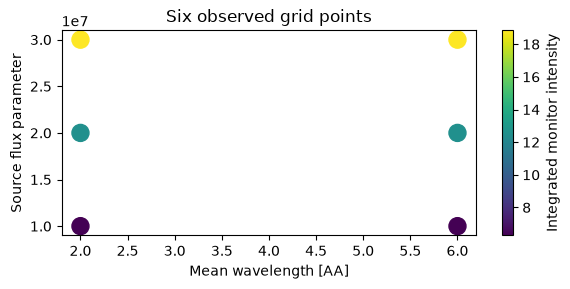

In [9]:
grid_log = output_root / 'grid.log'
!mcrun --force-compile --format=McCode --seed=314159 --ncount=50000 --dir="{grid_output}" "{instrument_file}" -M -N 2,3 wavelength=2,6 source_flux=1e7,3e7 > "{grid_log}" 2>&1
if _exit_code != 0:
    raise RuntimeError(grid_log.read_text())

grid_scan = ms.load_scan(grid_output)
grid_spectrum = grid_scan.dataset('spectrum')
assert len(grid_scan.points) == 6
assert grid_scan.plan is None
assert grid_spectrum.valid.all()
for point in grid_scan.points:
    print(point.point_id, point.parameters)

valid = grid_spectrum.valid
fig, ax = plt.subplots(figsize=(6, 3))
image = ax.scatter(grid_spectrum.coordinates['wavelength'][valid].astype(float),
                   grid_spectrum.coordinates['source_flux'][valid].astype(float),
                   c=grid_spectrum.total_I[valid], s=150, cmap='viridis')
ax.set(xlabel='Mean wavelength [AA]', ylabel='Source flux parameter',
       title='Six observed grid points')
fig.colorbar(image, ax=ax, label='Integrated monitor intensity')
fig.tight_layout()
plt.show()

## Read the same paired scan in NeXus format

A NeXus-enabled McStas installation can write the paired scan to a combined `mccode.h5`. We use a different output directory and `--force-compile`: changing the format alone can reuse an ASCII-only binary and silently fall back to ASCII.

Both a directory and an explicit HDF5 file can be passed to `load_scan()`. Each point records its file and entry locator. Combined-file point IDs describe **storage order**, not original requested-plan IDs; failed points can be omitted by the native writer. Repeated coordinates are still distinct measurements.

In [10]:
nexus_log = output_root / 'nexus.log'
!mcrun --force-compile --format=NeXus --seed=314159 --ncount=50000 --dir="{nexus_output}" "{instrument_file}" -N 3 wavelength=2,6 source_flux=1e7,3e7 > "{nexus_log}" 2>&1
if _exit_code != 0:
    raise RuntimeError(nexus_log.read_text())
assert (nexus_output / 'mccode.h5').is_file(), 'Check nexus.log for a format fallback.'

nexus_scan = ms.load_scan(nexus_output)
nexus_from_file = ms.load_scan(nexus_output / 'mccode.h5')
assert len(nexus_scan.points) == len(nexus_from_file.points) == 3
assert nexus_scan.metadata['point_id_basis'] == 'entry order'
np.testing.assert_allclose(nexus_scan.dataset('spectrum').total_I,
                           paired_spectrum.total_I, rtol=1e-5, atol=0)
for ascii_point, nexus_point in zip(paired_scan.points, nexus_scan.points):
    np.testing.assert_allclose(nexus_point.data.find('spectrum').Intensity,
                               ascii_point.data.find('spectrum').Intensity,
                               rtol=1e-5, atol=0)
    print(nexus_point.point_id, nexus_point.parameters, nexus_point.source.entry)
print('ASCII and NeXus detector histograms agree within text-output precision.')

0 {'source_flux': 10000000.0, 'wavelength': 2.0} /entry1
1 {'source_flux': 20000000.0, 'wavelength': 4.0} /entry2
2 {'source_flux': 30000000.0, 'wavelength': 6.0} /entry3
ASCII and NeXus detector histograms agree within text-output precision.


## Load a summary file without detector data

The original `mccode.dat` can be loaded directly; its neighbouring point directories are still available. To demonstrate a genuinely summary-only input, copy that file to a directory without numbered point metadata.

The copied summary still provides intensity/error pairs and wavelength coordinates. It does not contain detector histograms or count columns. Missing counts are represented by `NaN` with availability `False`, not by a measured zero. No monitor filename is invented for a summary-only identity.

In [11]:
from mcstasscript.data.scan import ScanDataError

from_original_summary = ms.load_scan(wavelength_output / 'mccode.dat')
summary_copy = output_root / 'wavelength_summary_only.dat'
shutil.copyfile(wavelength_output / 'mccode.dat', summary_copy)
summary_only = ms.load_scan(summary_copy)
assert len(summary_only.points) == 5
summary_spectrum = summary_only.dataset('spectrum')
np.testing.assert_allclose(summary_spectrum.total_I, spectrum.total_I)
assert summary_spectrum.monitor.filename is None
assert np.isnan(summary_spectrum.total_N).all()
assert all(point.source is None for point in summary_only.points)
print('Intensity:', summary_spectrum.total_I)
print('Counts:   ', summary_spectrum.total_N)
print('Count availability:', summary_spectrum.availability['total_N'])
try:
    summary_only.points[0].data
except ScanDataError:
    print('Expected: the copied summary has no full detector data.')

Intensity: [6.28297 6.28297 6.28297 6.28297 6.28297]
Counts:    [nan nan nan nan nan]
Count availability: [False False False False False]
Expected: the copied summary has no full detector data.


## Inspect incomplete output and reload later

Native files do not establish per-point execution success, so `point.status` remains `'unknown'` and `scan.execution` is empty. This is independent of `point.data_status`, which changes when full data is actually loaded. A missing summary value, an unreadable monitor, and an omitted requested point are different situations.

Check `scan.metadata['diagnostics']` for unresolved summary associations or native header limitations. A partial point can return its readable monitors with a warning and per-monitor `point.diagnostics`; an entirely unavailable point raises `ScanDataError`. In particular, never infer a complete grid or missing original plan IDs merely from a native header or NeXus entry name.

Later, or in another notebook, the only step needed for analysis is `saved_scan = ms.load_scan('data_folder/my_named_scan_examples/my_paired_scan')`. The `instrument` object, generated C code, and original notebook are not needed. McStas is needed to produce new data, not to read these saved results.

In [12]:
print('Native execution evidence:', scan.execution)
print('Execution statuses:       ', [point.status for point in scan.points])
print('Full-data statuses:       ', [point.data_status for point in scan.points])
print('Reader diagnostics:       ', scan.metadata['diagnostics'])
assert scan.execution == {}
assert all(point.status == 'unknown' for point in scan.points)

Native execution evidence: {}
Execution statuses:        ['unknown', 'unknown', 'unknown', 'unknown', 'unknown']
Full-data statuses:        ['available', 'unknown', 'available', 'unknown', 'available']
Reader diagnostics:        []
